In [1]:
import numpy as np
import pandas as pd
import os
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.feature_extraction import DictVectorizer
import seaborn as sns
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report, accuracy_score, roc_curve, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
os.chdir(r"D:\Virtual Environments\ML zoomcamp\Data") # Change according to your file directory

# Part 0: Introduction

# Part 1: EDA

In [2]:
df = pd.read_csv('diabetes-dataset-2k.csv')
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,0.32,0,0,No Info,20.56,6.6,126,0
1,Male,21.00,0,0,never,23.78,6.0,126,0
2,Female,15.00,0,0,never,16.27,6.0,160,0
3,Male,34.00,0,0,never,37.43,6.1,85,0
4,Female,44.00,0,0,former,23.49,4.5,80,0


In [3]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

No missing or null variables in the dataset

In [4]:
df.shape

(2000, 9)

In [5]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [53]:
convert = ['hypertension','heart_disease',]
df[convert] = df[convert].astype('category')

In [54]:
df.dtypes

gender                      str
age                     float64
hypertension           category
heart_disease          category
smoking_history             str
bmi                     float64
HbA1c_level             float64
blood_glucose_level       int64
diabetes                  int64
dtype: object

In [55]:
df.nunique()

gender                    2
age                      98
hypertension              2
heart_disease             2
smoking_history           3
bmi                    1108
HbA1c_level              18
blood_glucose_level      18
diabetes                  2
dtype: int64

In [56]:
df['diabetes'].value_counts(normalize=True)

diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

From the dataset, 91.5% of individuals do not have diabetes while 8.5% of individuals have diabetes. Given the vast difference in proportions, it will be important to consider stratifying the data when splitting.

In [57]:
df['smoking_history'] = df['smoking_history'].mask((df['smoking_history'] == 'current') |
                                                   (df['smoking_history'] == 'ever') |
                                                   (df['smoking_history'] == 'former'), 'yes')
df['smoking_history'] = df['smoking_history'].mask((df['smoking_history'] == 'never') |
                                                   (df['smoking_history'] == 'not current'), 'no')
df['smoking_history'] = df['smoking_history'].str.lower()

The response variable, diabetes, will be the target output that the model will be trying to predict. It has been changed to string whereby '0' represents no diabetes and '1' represents diabetes present. For simplicity, we will be categorising the variables in 'smoking_history' into 'yes', 'no' and 'no info'

## Checking The Association between response and input variables

In [58]:
corr_matrix = df.iloc[:,:-1].corr(numeric_only=True)
print(corr_matrix.round(2))

                      age   bmi  HbA1c_level  blood_glucose_level
age                  1.00  0.34         0.08                 0.11
bmi                  0.34  1.00         0.08                 0.14
HbA1c_level          0.08  0.08         1.00                 0.20
blood_glucose_level  0.11  0.14         0.20                 1.00


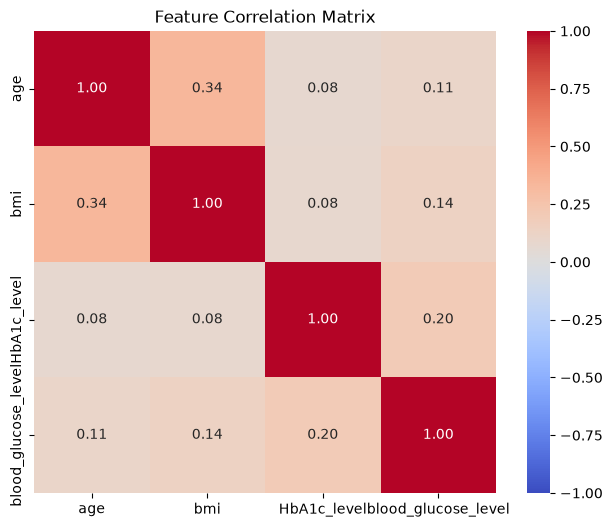

In [59]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,        
    fmt=".2f",         
    cmap="coolwarm",   
    vmin=-1, vmax=1,   
    square=True        
)
plt.title("Feature Correlation Matrix")
plt.show()

Some noticeable observations include moderate correlations between blood_glucose_level and diabetes (0.41), and between HbA1c_level and diabetes (0.42). The other variables display weak correlations with one another (below 0.30). There were no negative correlations.

# Part 2: Methods

Logistic Regression vs XGBoost vs Random Forest


## Splitting Dataset to form Test and Train splits

In [11]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1101,
    stratify=df['diabetes']
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1101,
    stratify=df_full_train['diabetes']
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

response = 'diabetes'
numerical = ['age', 'bmi', 'blood_glucose_level', 'HbA1c_level']
categorical = ['hypertension', 'heart_disease', 'smoking_history', 'gender']

y_train = df_train[response].values
y_val = df_val[response].values

In [12]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

## XGBoost

In [13]:
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [14]:
#Setting a baseline model
params = {
    'eta': 0.3,              
    'max_depth': 6,          
    'min_child_weight': 1,   
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1101
}

watchlist = [(dtrain, 'train'), (dval, 'val')]

model = xgb.train(
    params,
    dtrain,
    num_boost_round=100,
    evals=watchlist,
    verbose_eval=5
)

[0]	train-auc:0.95171	val-auc:0.94270
[5]	train-auc:0.98976	val-auc:0.97131
[10]	train-auc:0.99201	val-auc:0.97637
[15]	train-auc:0.99588	val-auc:0.97706
[20]	train-auc:0.99866	val-auc:0.97686
[25]	train-auc:0.99972	val-auc:0.97549
[30]	train-auc:0.99998	val-auc:0.97332
[35]	train-auc:1.00000	val-auc:0.97380
[40]	train-auc:1.00000	val-auc:0.97541
[45]	train-auc:1.00000	val-auc:0.97565
[50]	train-auc:1.00000	val-auc:0.97437
[55]	train-auc:1.00000	val-auc:0.97453
[60]	train-auc:1.00000	val-auc:0.97461
[65]	train-auc:1.00000	val-auc:0.97477
[70]	train-auc:1.00000	val-auc:0.97581
[75]	train-auc:1.00000	val-auc:0.97573
[80]	train-auc:1.00000	val-auc:0.97485
[85]	train-auc:1.00000	val-auc:0.97581
[90]	train-auc:1.00000	val-auc:0.97469
[95]	train-auc:1.00000	val-auc:0.97453
[99]	train-auc:1.00000	val-auc:0.97477


In [15]:
scores = {}

for max_depth in [3, 4, 6, 10]:
    for min_child_weight in [1, 5, 10]:
        
        params = {
            'eta': 0.1,
            'max_depth': max_depth,
            'min_child_weight': min_child_weight,
            'objective': 'binary:logistic',
            'eval_metric': 'auc',
            'seed': 1101
        }
        
        # Train model over 100 rounds
        model = xgb.train(params, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=False)
        
        # Predict on validation set
        y_pred = model.predict(dval)
        auc = roc_auc_score(y_val, y_pred)
        
        key = f"depth_{max_depth}_min_child_{min_child_weight}"
        scores[key] = auc
        print(f"{key} -> val AUC: {auc:.4f}")

# Find the configuration with the highest validation AUC
best_config = max(scores, key=scores.get)
print(f"\nBest Configuration: {best_config} with AUC: {scores[best_config]:.4f}")

depth_3_min_child_1 -> val AUC: 0.9699
depth_3_min_child_5 -> val AUC: 0.9620
depth_3_min_child_10 -> val AUC: 0.9480
depth_4_min_child_1 -> val AUC: 0.9736
depth_4_min_child_5 -> val AUC: 0.9622
depth_4_min_child_10 -> val AUC: 0.9476
depth_6_min_child_1 -> val AUC: 0.9788
depth_6_min_child_5 -> val AUC: 0.9660
depth_6_min_child_10 -> val AUC: 0.9495
depth_10_min_child_1 -> val AUC: 0.9784
depth_10_min_child_5 -> val AUC: 0.9658
depth_10_min_child_10 -> val AUC: 0.9495

Best Configuration: depth_6_min_child_1 with AUC: 0.9788


In [16]:
scores = {}

for eta in [0.3, 0.1, 0.05, 0.01]:
    
    params = {
        'eta': eta,
        'max_depth': 6,          
        'min_child_weight': 1,   
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'seed': 1101             
    }
    
    model = xgb.train(params, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=False)
    
    y_pred = model.predict(dval)
    auc = roc_auc_score(y_val, y_pred)
    
    scores[eta] = auc
    print(f"eta: {eta} -> val AUC: {auc:.4f}")

best_eta = max(scores, key=scores.get)
print(f"\nBest eta: {best_eta} with AUC: {scores[best_eta]:.4f}")

eta: 0.3 -> val AUC: 0.9748
eta: 0.1 -> val AUC: 0.9788
eta: 0.05 -> val AUC: 0.9782
eta: 0.01 -> val AUC: 0.9685

Best eta: 0.1 with AUC: 0.9788


In [17]:
final_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 1101
}

In [18]:
full_train_dicts = df_full_train[categorical + numerical].to_dict(orient='records')
test_dicts = df_test[categorical + numerical].to_dict(orient='records')

X_full_train = dv.transform(full_train_dicts)
X_test = dv.transform(test_dicts)

y_full_train = df_full_train[response].values
y_test = df_test[response].values

features = list(dv.get_feature_names_out())
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features)

In [62]:
final_model = xgb.train(
    final_params,
    dfulltrain,
    num_boost_round=100
)

In [64]:
y_test_pred = final_model.predict(dtest)
final_test_auc = roc_auc_score(y_test, y_test_pred)
print(f"XGBoost ROC AUC: {final_test_auc:.4f}")

XGBoost ROC AUC: 0.9584


In [33]:
y_test_pred_xgb_binary = (y_test_pred >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(y_test, y_test_pred_xgb_binary))

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       366
           1       0.81      0.65      0.72        34

    accuracy                           0.96       400
   macro avg       0.89      0.82      0.85       400
weighted avg       0.95      0.96      0.96       400



## Logistic Regression

In [60]:
def mutual_info_diabetes_score(series):
    return mutual_info_score(series, df_full_train['diabetes'])

mi = df_full_train[categorical].apply(mutual_info_diabetes_score)

mi = mi.sort_values(ascending=False)
print(mi)

heart_disease      0.015784
smoking_history    0.010481
hypertension       0.004310
gender             0.001746
dtype: float64


In [61]:
lr_model = LogisticRegression(solver='liblinear', random_state=1101, max_iter=1000)
lr_model.fit(X_full_train, y_full_train)
y_pred_lr = lr_model.predict_proba(X_test)[:, 1]

lr_test_auc = roc_auc_score(y_test, y_pred_lr)
print(f"Logistic Regression Test ROC AUC: {lr_test_auc:.4f}")

Logistic Regression Test ROC AUC: 0.9474


In [25]:
scores = {}
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

for c in C_values:
    lr_tuned = LogisticRegression(solver='liblinear', C=c, random_state=1101, max_iter=1000)
    lr_tuned.fit(X_train, y_train)
    y_val_pred = lr_tuned.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_val_pred)
    scores[c] = auc
    print(f"C: {c} -> val AUC: {auc:.4f}")

best_c = max(scores, key=scores.get)
print(f"\nBest C: {best_c} with AUC: {scores[best_c]:.4f}")

C: 0.001 -> val AUC: 0.4669
C: 0.01 -> val AUC: 0.5432
C: 0.1 -> val AUC: 0.8292
C: 1 -> val AUC: 0.9510
C: 10 -> val AUC: 0.9544
C: 100 -> val AUC: 0.9530

Best C: 10 with AUC: 0.9544


In [30]:
final_lr_model = LogisticRegression(solver='liblinear', C=10, random_state=1101, max_iter=1000)
final_lr_model.fit(X_full_train, y_full_train)
y_pred_lr = final_lr_model.predict_proba(X_test)[:, 1]

lr_test_auc = roc_auc_score(y_test, y_pred_lr)
print(f"Logistic Regression Test ROC AUC: {lr_test_auc:.4f}")

Logistic Regression Test ROC AUC: 0.9453


In [48]:
y_test_pred_lr = (y_pred_lr >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(y_test, y_test_pred_lr))

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       366
           1       0.90      0.56      0.69        34

    accuracy                           0.96       400
   macro avg       0.93      0.78      0.83       400
weighted avg       0.96      0.96      0.95       400



## Random Forest

In [37]:
scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1101, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append((n, auc))
    print(f"n_estimators={n:3d} -> AUC: {auc:.4f}")

best_n = max(scores, key=lambda x: x[1])[0]
print(f"\nBest n_estimators: {best_n}")

n_estimators= 10 -> AUC: 0.9209
n_estimators= 20 -> AUC: 0.9381
n_estimators= 30 -> AUC: 0.9371
n_estimators= 40 -> AUC: 0.9510
n_estimators= 50 -> AUC: 0.9510
n_estimators= 60 -> AUC: 0.9493
n_estimators= 70 -> AUC: 0.9469
n_estimators= 80 -> AUC: 0.9483
n_estimators= 90 -> AUC: 0.9504
n_estimators=100 -> AUC: 0.9550
n_estimators=110 -> AUC: 0.9576
n_estimators=120 -> AUC: 0.9575
n_estimators=130 -> AUC: 0.9593
n_estimators=140 -> AUC: 0.9591
n_estimators=150 -> AUC: 0.9584
n_estimators=160 -> AUC: 0.9582
n_estimators=170 -> AUC: 0.9582
n_estimators=180 -> AUC: 0.9597
n_estimators=190 -> AUC: 0.9600
n_estimators=200 -> AUC: 0.9593

Best n_estimators: 190


In [42]:
scores = []

for d in [5, 10, 15, 20, None]:
    rf = RandomForestClassifier(
        n_estimators=best_n, 
        max_depth=d, 
        random_state=1101, 
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    
    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append((d, auc))
    print(f"max_depth={str(d):4s} -> val AUC: {auc:.4f}")
best_depth = max(scores, key=lambda x: x[1])[0]
print(best_depth)

max_depth=5    -> val AUC: 0.9562
max_depth=10   -> val AUC: 0.9577
max_depth=15   -> val AUC: 0.9606
max_depth=20   -> val AUC: 0.9600
max_depth=None -> val AUC: 0.9600
15


In [43]:
scores = []

for s in [1, 2, 3, 5, 10]:
    rf = RandomForestClassifier(
        n_estimators=best_n,
        max_depth=best_depth,
        min_samples_leaf=s,
        random_state=1101,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    
    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append((s, auc))
    print(f"min_samples_leaf={s:2d} -> val AUC: {auc:.4f}")
best_min = max(scores, key=lambda x: x[1])[0]
print(best_min)

min_samples_leaf= 1 -> val AUC: 0.9606
min_samples_leaf= 2 -> val AUC: 0.9612
min_samples_leaf= 3 -> val AUC: 0.9597
min_samples_leaf= 5 -> val AUC: 0.9576
min_samples_leaf=10 -> val AUC: 0.9513
2


In [44]:
final_rf_model = RandomForestClassifier(
    n_estimators=190,
    max_depth=15,
    min_samples_leaf=2,
    random_state=1101,
    n_jobs=-1
)

In [47]:
final_rf_model.fit(X_full_train, y_full_train)

y_pred_rf_test = final_rf_model.predict_proba(X_test)[:, 1]
rf_test_auc = roc_auc_score(y_test, y_pred_rf_test)
print(f"Random Forest Test ROC AUC: {rf_test_auc:.4f}")

Random Forest Test ROC AUC: 0.9555


In [46]:
y_test_pred_rf_binary = (y_pred_rf_test >= 0.50).astype(int)
print("Random Forest Classification Report:")
print(classification_report(y_test, y_test_pred_rf_binary))

Random Forest Test ROC AUC: 0.9555

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       366
           1       1.00      0.65      0.79        34

    accuracy                           0.97       400
   macro avg       0.98      0.82      0.88       400
weighted avg       0.97      0.97      0.97       400

